Most of the prevalence model's initial conditions can be copied from [the 2011 PNAS paper describing the RTM](https://www.pnas.org/content/108/45/18238).
However, there are two differences that mean that not everything can be carried over; these both arise from using a survey determining prevalence as the data source rather than an incidence-based measure such as deaths or GP visits.
First, Paul's implementation uses the number of people in each state, as this can be related through the IFR to the number of people dieing, while I model the proportion of each strata in each state, as this then relates directly to the expected proportion of people testing positive in the survey.
Second, the use of a prevalence-based rather than incidence-based measure makes the concept of a hazard of experiencing the event less clear (at least to me).

The first two sections cover two issues that arise from this: first parameterising the initial proportion of people who are infectious, and second the inital proportion of people in each of the prevalence states.
The final section looks at the initial growth rate, comparing the model parameter to model outputs as previously discussed.

# Initial number of infections

Equations S5 and S6 give the calculation of how many infectious individuals there are at time 0 in the RTM:

$$
\begin{aligned}
I_{+} &= \sum_{a} I_{a}^{\text {tot }}=\frac{d_{I} \lambda_{0} \sum_{a} N_{a}}{R_{0}^{i n i t}} \\
I_{a}^{\text {tot }} &= I_{+} \chi_{a}^{M}
\end{aligned}
$$

Where:

* $I_+$ is the total number of individuals infectious at time 0 (derived parameter).
* $I_a^\text{tot}$ is the total number of individuals infectious at time 0 in age group $a$ (derived parameter).
* $d_I$ is the mean length of the infectious period (estimated parameter).
* $\lambda_0$ is the average initial hazard of infection (estimated parameter).
* $N_a$ is the population size in age group $a$ (assumed).
* $\chi_a^M$ is element $a$ of the eigenvector corresponding to the dominant eigenvalue of the transmission matrix, with the vector scaled so that its elements sum to 1. This vector's interpretation is the distribution of infections in the steady-state of initial exponential growth (combination of derived parameters and assumptions).

Adopting the convention that lower-case letters represent the proportion of the stratum in the state (eg: $I_a^\text{tot} = i_a^\text{tot}/N_a$), what the prevalence model needs is $i_a^\text{tot}$.
This requires using $N_a / \sum_a N_a$ (the proportion of the population in each age group) if derived from the above equations.
Apart from this, $N_a$ does not appear in any model equations, so it is odd to me that it should in the initial conditions.

Currently, I am instead using a parameter $i_0$ that represents the proportion of the population in the age group with the most initial infectious individuals that are initial infected. Ie: $i_a^\text{tot} = i_0$ when $a$ corresponds to the element of $\chi^M$ with the largest magnitude.
Hence:
$$
i_a^\text{tot} = i_0 \frac{\chi_a^M}{\max_a \chi_a^M}.
$$

# Initial states of compartments

The equations between S3 and S4 give the starting state for the model compartments in terms of $I^\text{tot}$; the initial growth rate $\psi_r$; the rate of leaving the E and I compartments, $\sigma$ and $\gamma$ respectively, and the timestep used for discreteising the ODEs, $\delta t$:
$$
\begin{aligned}
\alpha &= \exp(\psi_r \delta t) \\
I_{1}(0, a)&=I_{a}^{\mathrm{tot}}\left(1+\frac{\epsilon \gamma \delta t}{\alpha+\gamma \delta t}\right)^{-1} \\
I_{2}(0, a)&=\left(I_{a}^{\mathrm{lot}}-I_{1}(0, a)\right) \\
E_{2}(0, a)&=I_{1}(0, a) \frac{\alpha+\gamma \delta t}{\sigma \delta t} \\
E_{1}(0, a)&=E_{2}(0, a) \frac{\alpha+\sigma \delta t}{\sigma \delta t}
\end{aligned}
$$

Some questions:

1. What is $\epsilon$? I can't see it defined anywhere in the paper, and it was set to 1 in the code I copied.
1. How are these equations derived? I think I should do something similar for the prevalence compartments but can't work it out.
1. It seems odd that the number of people in each compartment should depend on $\delta t$ (ie: the granularity of the discretisation). Is there an intuition for this?

# Initial growth rate

As discussed previously, the theoretical initial growth rate, $\psi_r$, does not always reflect the realised growth rate in the model.
There are a few reasons I can think of that this can happen:

* $\psi_r$, as defined in the PNAS paper, is for a fully susceptible population. I am not sure why this is, as it should (I think fairly easily) be possible to adjust equations S2--S5 so that they are in terms of $R_e(0)$, the effective reproduction number at time 0, and the effective growth rate. My intuition is that this quantity should be more identifiable, since this should reflect the growth rate in the data initially.
* The first approx two days of the model run has a different growth rate, possibly due to a steady-state assumption in the derivation of $\psi_r$. I am confused by this, as I thought initialising the model using the equations above should avoid this.
* Even at very low prevelance and over short timescales, the number of initial infected individuals can matter. For example, with $\psi_r = 0.05$, a fully susceptible population, and 1 in 1,000,000 indididuals initially infected, the average growth rate over days 2 to 10 is 0.050 while with 1 in 1,000 initially infectious it is 0.0489. Over days 2 to 9 (ie: the first week ignoring a period to obtain steady-state), this is 0.0497 and 0.0481 respectively. 

In [1]:
import os
try:
    os.chdir("experiments")
except:
    pass
os.chdir("..")
os.getcwd()

'/home/joshuab/COVID/SEIR_prevalence/covid19'

In [2]:
import plotnine as pn
import numpy as np
import pandas as pd
from datetime import date, timedelta
from math import ceil
from models import prevalence_model, logPDF_prev, params
from scipy import stats, optimize

In [24]:
start_date = date(2020, 8, 31)
end_date = date(2020, 10, 1)
dates = pd.date_range(start_date, end_date, freq="1D").date
n_days = (end_date - start_date).days + 1
n_weeks = n_days / 7
n_matrices = ceil(n_weeks)
matrix_dates = pd.date_range(start_date, end_date-timedelta(days=1), freq="7D")
assert len(matrix_dates) == n_matrices
matrices_list = []
for d in matrix_dates:
    file = "contact_m/2021-08-27/England/{}.csv".format(d.date())
    matrices_list.append(np.loadtxt(file, delimiter=","))
matrices = np.stack(matrices_list)
n_strata = matrices.shape[1]
assert n_strata == 6

In [4]:
model_no_change = prevalence_model.SingleRegionStratifiedSEIRCompartmental(matrices[0:1], n_days, beta_step_spacing=100)

Each of the following model runs displays average growth rate in the daily incidence of infections for each age group by age as well as a plot of the daily incidence of infections on a log scale.
The average growth rate between day $i$ and $j$ for age group $a$ is calculated as $\frac{\log \Delta_a(j) - \log \Delta_a(i)}{j - i}$ where $\Delta_a(i)$ is the proportion of age group $a$ infected on day $i$.

In [21]:
def check_growth(result):
    nni, _, _ = result
    log_nni = np.log(nni)
    print("Entire period average growth rate: {}".format((log_nni[-1] - log_nni[0]) / (len(nni) - 1)))
    print("Days 1 to 2 average growth rate: {}".format((log_nni[2] - log_nni[1])))
    print("Days 2 to 5 average growth rate: {}".format((log_nni[5] - log_nni[2]) / 3))
    print("Days 4 to 9 average growth rate: {}".format((log_nni[9] - log_nni[4]) / 5))
    print("Days 2 to 9 average growth rate: {}".format((log_nni[9] - log_nni[2]) / 7))
    return (pn.ggplot(None) +
     pn.geom_point(pn.aes(x=range(len(log_nni[:,3])), y=log_nni[:,3])) +
     pn.geom_smooth(pn.aes(x=range(len(log_nni[:,3])), y=log_nni[:,3]), method="lm")
    )

Using a single matrix, with $\psi_r = 0.05$, $i_0 = 10^{-6}$ ($i_0$ as defined in section 1), a fully susceptible population, and Edwin's matrix for contacts corresponding to week beginning 31st August 2020.
The calculated growth rates are almost 0.05, as expected.

Entire period average growth rate: [0.04865821 0.04865763 0.04865806 0.04865822 0.04865865 0.04865892]
Days 1 to 2 average growth rate: [0.04591417 0.04591393 0.0459141  0.04591417 0.04591436 0.04591449]
Days 2 to 5 average growth rate: [0.05018828 0.05018799 0.05018821 0.05018829 0.05018851 0.05018866]
Days 4 to 9 average growth rate: [0.04932502 0.04932468 0.04932493 0.04932503 0.04932528 0.04932544]
Days 2 to 9 average growth rate: [0.04973246 0.04973213 0.04973237 0.04973246 0.0497327  0.04973286]


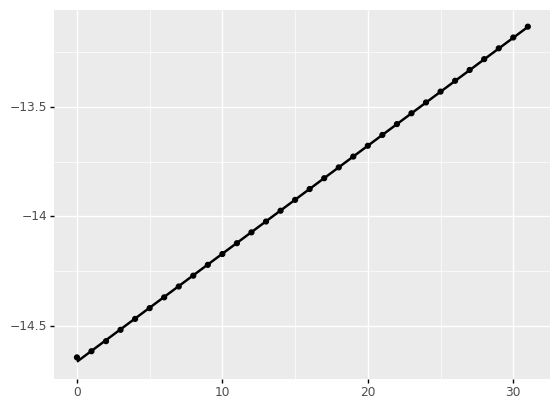

<ggplot: (-9223363243158965865)>

In [22]:
check_growth(model_no_change.simulate(beta=[], dL=2, dI=2, psir=0.05, i0=1e-6, pi=np.ones(matrices.shape[1]), matrix_modifiers=np.ones(matrices.shape[1:])))

As previous, but $i_0 = 10^{-3}$, comparable to the ONS prevalence estimate for early September.
Growth rates decrease noticeably even over one week.

Entire period average growth rate: [0.0442909  0.0437395  0.04414992 0.04430131 0.04471163 0.04497814]
Days 1 to 2 average growth rate: [0.045043   0.04480364 0.04497586 0.04504418 0.04523355 0.04535993]
Days 2 to 5 average growth rate: [0.04893509 0.04864157 0.04885788 0.04894098 0.04916162 0.04930631]
Days 4 to 9 average growth rate: [0.04755734 0.04721909 0.04747055 0.04756404 0.04781502 0.04797795]
Days 2 to 9 average growth rate: [0.04813266 0.04780903 0.04804898 0.04813911 0.04838018 0.04853719]


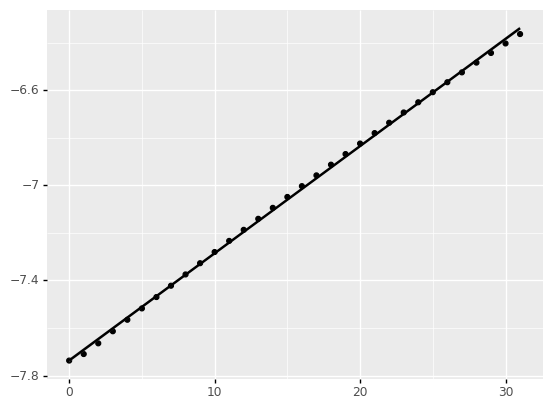

<ggplot: (8793695771042)>

In [23]:
check_growth(model_no_change.simulate(beta=[], dL=2, dI=2, psir=0.05, i0=1e-3, pi=np.ones(matrices.shape[1]), matrix_modifiers=np.ones(matrices.shape[1:])))

Going back to the first model, but putting 10% of people in the removed compartment at time zero.
This dramatically reduces the initial growth rate.

Entire period average growth rate: [0.01889573 0.01889537 0.01889564 0.01889574 0.018896   0.01889616]
Days 1 to 2 average growth rate: [0.01977622 0.01977598 0.01977616 0.01977623 0.01977641 0.01977654]
Days 2 to 5 average growth rate: [0.0184776  0.01847731 0.01847752 0.01847761 0.01847782 0.01847795]
Days 4 to 9 average growth rate: [0.01871629 0.01871598 0.01871621 0.0187163  0.01871651 0.01871666]
Days 2 to 9 average growth rate: [0.01860407 0.01860377 0.01860399 0.01860407 0.01860429 0.01860443]


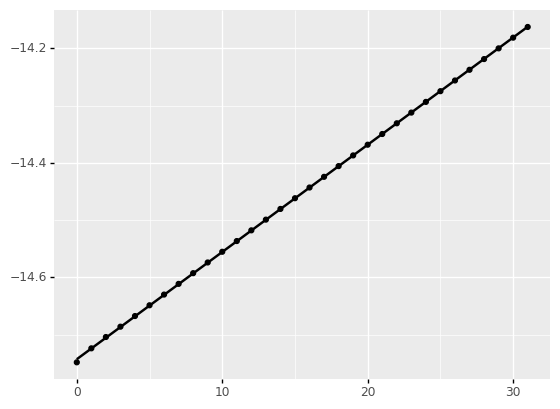

<ggplot: (-9223363243159186295)>

In [31]:
check_growth(model_no_change.simulate(beta=[], dL=2, dI=2, psir=0.05, i0=1e-6, pi=np.ones(matrices.shape[1])*0.9, matrix_modifiers=np.ones(matrices.shape[1:])))

As the first run but with reducing the susceptibility in children. As expected, the growth rates remain close to their theoretical values.

Entire period average growth rate: [0.04865833 0.04865829 0.04865823 0.04865746 0.04865787 0.0486583 ]
Days 1 to 2 average growth rate: [0.04591434 0.04591431 0.04591429 0.04591394 0.04591413 0.04591432]
Days 2 to 5 average growth rate: [0.05018845 0.05018843 0.0501884  0.050188   0.05018821 0.05018844]
Days 4 to 9 average growth rate: [0.04932518 0.04932515 0.04932511 0.04932466 0.0493249  0.04932516]
Days 2 to 9 average growth rate: [0.04973262 0.0497326  0.04973256 0.04973212 0.04973236 0.0497326 ]


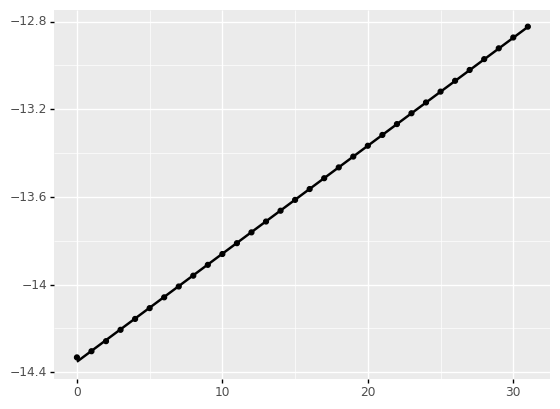

<ggplot: (-9223363243158904481)>

In [26]:
reduce_children = np.ones(matrices.shape[1:])
reduce_children[:3,:] = 0.5
check_growth(model_no_change.simulate(beta=[], dL=2, dI=2, psir=0.05, i0=1e-6, pi=np.ones(matrices.shape[1]), matrix_modifiers=reduce_children))

As previous (ie: with reduced susceptibility in children), but using Edwin's matrix for the start of September.

As the first run but switching to the matrix for the week beginning 7th Sep 20 days in.
The growth rate over the whole period is higher than $\psi_r$ due to the increasing mobility.

Entire period average growth rate: [0.05992931 0.0658907  0.05630243 0.05647012 0.05519854 0.05412714]
Days 1 to 2 average growth rate: [0.04591434 0.04591431 0.04591429 0.04591394 0.04591413 0.04591432]
Days 2 to 5 average growth rate: [0.05018845 0.05018843 0.0501884  0.050188   0.05018821 0.05018844]
Days 4 to 9 average growth rate: [0.04932518 0.04932515 0.04932511 0.04932466 0.0493249  0.04932516]
Days 2 to 9 average growth rate: [0.04973262 0.0497326  0.04973256 0.04973212 0.04973236 0.0497326 ]


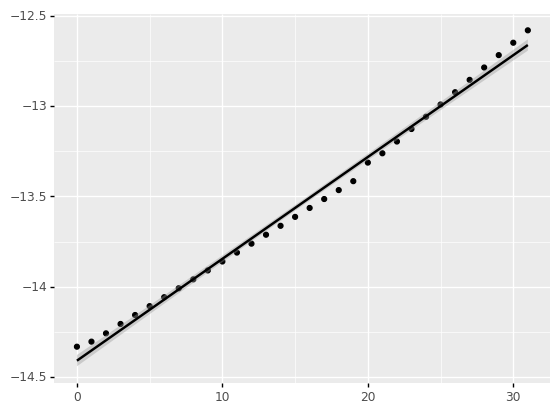

<ggplot: (-9223363243159100626)>

In [28]:
model_two_matrices = prevalence_model.SingleRegionStratifiedSEIRCompartmental(matrices[0:2], n_days, beta_step_spacing=20)
check_growth(model_two_matrices.simulate(beta=[1], dL=2, dI=2, psir=0.05, i0=1e-6, pi=np.ones(matrices.shape[1]), matrix_modifiers=reduce_children))

# Initial infections con

Following on from our conversation on Thursday morning, I failed to understand what was happening.
We want to justify that $\lambda_0 = I_+ R_0 / d_I N$ is an identifiable quantity.

1. $R_0 / d_I$ is the rate (number per unit time) at which a infections occur per infectious indvidual when $R_0$ applies (units: $\text{time}^{-1}$ as $R_0$ is dimensionless and $d_I$ has units time).
1. $I_+ R_0 / d_I$ is the rate at which new infections occur across the whole population (units: $\text{people} \cdot \text{time}^{-1}$).
1. $I_+ R_0 / d_I N$ is the average hazard (probability per unit time) of being infected for a member of the poulation (units: $\text{time}^{-1}$).